# Bài kiểm tra 2 – Xây dựng, huấn luyện và đánh giá mô hình
**Đề tài:** So sánh các thuật toán học máy truyền thống trong dự đoán tương tác thuốc dựa trên cấu trúc hóa học
**Đầu vào:** `data/processed/dataset_pairs.csv.gz`, `drugs_clean.csv` (tạo bởi `01_EDA_TienXuLy.ipynb`)

| Mục | Nội dung | Tiêu chí KT2 |
|---|---|---|
| 1 | Đọc dữ liệu, tạo đặc trưng vân tay (Morgan + MACCS) | 4 |
| 2 | Mô hình cơ sở và các thuật toán, tổ chức thành `Pipeline` | 1, 2, 3 |
| 3 | Kiểm định chéo phân tầng 5-fold trên tập huấn luyện (trung bình ± độ lệch chuẩn, train vs validation) | 5, 6 |
| 4 | SVM nhân RBF trên fold 1 (giới hạn thời gian) | 1, 6 |
| 5 | Huấn luyện lại trên toàn bộ tập huấn luyện, đánh giá **một lần** trên tập kiểm tra; ROC, ma trận nhầm lẫn | 5, 6 |
| 6 | Phân tích lỗi: nhóm dữ liệu dự đoán sai nhiều, quá khớp/chưa khớp | 7 |
| 7 | Đặc trưng ảnh hưởng nhiều đến dự đoán | 9 |

Chạy: mở notebook trong thư mục `notebooks/`, chọn *Run All*. Chạy lần đầu mất khoảng 50–60 phút trên CPU 2 nhân (phần lớn là Random Forest và SVM); các bước tốn thời gian được lưu vào `results/cache/` nên các lần chạy sau chỉ mất vài phút (xóa `results/cache/` để tính lại từ đầu). Mọi bước ngẫu nhiên dùng `SEED = 42`.

In [1]:
import os, sys, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import DataStructs
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import (roc_auc_score, f1_score, recall_score, precision_score, accuracy_score,
                             confusion_matrix, roc_curve)
from xgboost import XGBClassifier
sys.path.insert(0, "../src")
from ddi_features import load_data, fingerprints, build_pairs, feature_names, to_float32, maccs_description, morgan_bit_fragments, cached
warnings.filterwarnings("ignore")

SEED = 42
PROC, RES, FIG = "../data/processed", "../results", "../LaTeX/images"
CACHE = f"{RES}/cache"                      # kết quả trung gian đã tính (xóa để chạy lại từ đầu)
os.makedirs(RES, exist_ok=True); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
BLUE, NAVY, LB, OR, GR, RED = "#1B75BB", "#0E3A66", "#9CC3E6", "#F2A541", "#B0B7C3", "#C0392B"
SUM = {}                                    # mọi số liệu dùng trong báo cáo -> results/bkt2_summary.json
QUICK = os.environ.get("DDI_QUICK") == "1"  # chạy thử nhanh trên tập con (mặc định: tắt)
def savefig(name):
    plt.savefig(f"{FIG}/{name}", bbox_inches="tight"); plt.show()

## 1. Đọc dữ liệu và tạo đặc trưng

In [2]:
drugs, pairs = load_data(PROC)
fps = fingerprints(drugs)                   # Morgan r=2 (1.024 bit), Morgan đếm, MACCS (167 bit) cho 2.472 thuốc
train_df = pairs[pairs.split == "train"].reset_index(drop=True)
test_df = pairs[pairs.split == "test"].reset_index(drop=True)
X_train = build_pairs(train_df, drugs, fps, "concat"); y_train = train_df.label.values
X_test = build_pairs(test_df, drugs, fps, "concat"); y_test = test_df.label.values
FEAT = np.array(feature_names("concat"))
if QUICK:
    X_train, y_train, train_df = X_train[:4000], y_train[:4000], train_df.iloc[:4000]
    X_test, y_test, test_df = X_test[:2000], y_test[:2000], test_df.iloc[:2000]
print("Tập huấn luyện:", X_train.shape, "– tỷ lệ dương", y_train.mean())
print("Tập kiểm tra:  ", X_test.shape, "– tỷ lệ dương", y_test.mean())

Tập huấn luyện: (80000, 2382) – tỷ lệ dương 0.5
Tập kiểm tra:   (20000, 2382) – tỷ lệ dương 0.5


## 2. Mô hình cơ sở và các thuật toán (Pipeline)
- **Mô hình cơ sở:** `DummyClassifier` (dự đoán xác suất theo tỷ lệ lớp, nhãn theo lớp đa số) và **Logistic Regression** tham số mặc định (mốc tuyến tính).
- **Random Forest**, **XGBoost**: mô hình cây, nắm bắt tương tác giữa các bit, không cần chuẩn hóa.
- **SVM nhân RBF**: chạy riêng ở mục 4 vì thời gian huấn luyện tăng theo bình phương số mẫu.

Mọi bước tiền xử lý nằm trong `Pipeline` nên được fit lại trên từng fold huấn luyện – không rò rỉ dữ liệu.

In [3]:
def make_models():
    f32 = ("float32", FunctionTransformer(to_float32))
    return {
        "Dummy": Pipeline([("clf", DummyClassifier(strategy="prior"))]),
        "Logistic Regression": Pipeline([f32, ("loc_hang_so", VarianceThreshold(0.0)), ("chuan_hoa", StandardScaler()),
                                         ("clf", LogisticRegression(C=1.0, max_iter=3000, random_state=SEED))]),
        "Random Forest": Pipeline([("loc_hang_so", VarianceThreshold(0.0)),
                                   ("clf", RandomForestClassifier(n_estimators=300, max_features="sqrt", n_jobs=2, random_state=SEED))]),
        "XGBoost": Pipeline([("loc_hang_so", VarianceThreshold(0.0)),
                             ("clf", XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1, subsample=0.8,
                                                   colsample_bytree=0.5, tree_method="hist", n_jobs=2,
                                                   eval_metric="logloss", random_state=SEED))]),
    }
for k, v in make_models().items(): print(k, "->", v.steps[-1][1])

Dummy -> DummyClassifier()
Logistic Regression -> LogisticRegression(max_iter=3000, random_state=42)
Random Forest -> RandomForestClassifier(n_estimators=300, n_jobs=2, random_state=42)
XGBoost -> XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.5, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=400, n_jobs=2,
              num_parallel_tree=None, ...)


## 3. Kiểm định chéo phân tầng 5-fold trên tập huấn luyện

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision", "accuracy": "accuracy"}
rows = []
for name, model in make_models().items():
    t0 = time.time()
    r = cached(f"{CACHE}/bkt2_cv_{name.replace(' ', '_')}{'_quick' if QUICK else ''}.joblib",
               lambda: cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, error_score="raise"))
    for k in range(5):
        rows.append({"Mô hình": name, "Fold": k + 1, **{m: r[f"test_{m}"][k] for m in SCORING},
                     **{f"train_{m}": r[f"train_{m}"][k] for m in SCORING}, "fit_time": r["fit_time"][k]})
    print(f"{name:20s} ROC-AUC = {r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f}  ({time.time() - t0:.0f} s)")
cv_df = pd.DataFrame(rows); cv_df.to_csv(f"{RES}/bkt2_cv_folds.csv", index=False)

Dummy                ROC-AUC = 0.5000 ± 0.0000  (0 s)
Logistic Regression  ROC-AUC = 0.8067 ± 0.0026  (0 s)
Random Forest        ROC-AUC = 0.8582 ± 0.0022  (0 s)
XGBoost              ROC-AUC = 0.8470 ± 0.0017  (0 s)


In [5]:
METRICS = ["roc_auc", "f1", "recall", "precision", "accuracy"]
agg = cv_df.groupby("Mô hình", sort=False)
cv_table = pd.DataFrame({m: agg[m].mean().map("{:.4f}".format) + " ± " + agg[m].std(ddof=0).map("{:.4f}".format) for m in METRICS})
cv_table["Thời gian fit (s/fold)"] = agg["fit_time"].mean().round(1)
display(cv_table)
gap = pd.DataFrame({"ROC-AUC train": agg["train_roc_auc"].mean(), "ROC-AUC validation": agg["roc_auc"].mean()})
gap["Chênh lệch"] = gap["ROC-AUC train"] - gap["ROC-AUC validation"]
display(gap.round(4))
SUM["cv"] = {n: {**{m: [float(agg[m].mean()[n]), float(agg[m].std(ddof=0)[n])] for m in METRICS},
                 "train_roc_auc": float(agg["train_roc_auc"].mean()[n]), "train_f1": float(agg["train_f1"].mean()[n]),
                 "fit_time": float(agg["fit_time"].mean()[n])} for n in cv_table.index}

,roc_auc,f1,recall,precision,accuracy,Thời gian fit (s/fold)
Mô hình,,,,,,
Dummy,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0
Logistic Regression,0.8067 ± 0.0026,0.7386 ± 0.0025,0.7562 ± 0.0028,0.7218 ± 0.0027,0.7324 ± 0.0026,22.9
Random Forest,0.8582 ± 0.0022,0.7834 ± 0.0028,0.8091 ± 0.0049,0.7594 ± 0.0022,0.7764 ± 0.0025,75.6
XGBoost,0.8470 ± 0.0017,0.7726 ± 0.0015,0.7993 ± 0.0032,0.7475 ± 0.0016,0.7647 ± 0.0013,45.4


,ROC-AUC train,ROC-AUC validation,Chênh lệch
Mô hình,,,
Dummy,0.5000,0.5000,0.0000
Logistic Regression,0.8365,0.8067,0.0298
Random Forest,1.0000,0.8582,0.1418
XGBoost,0.9277,0.8470,0.0806


## 4. SVM nhân RBF trên fold 1
Huấn luyện SVM trên toàn bộ 64.000 mẫu của một fold mất vài giờ (độ phức tạp xấp xỉ bậc hai theo số mẫu), nên SVM
được huấn luyện trên **20.000 mẫu lấy ngẫu nhiên phân tầng từ phần huấn luyện của fold 1** và đánh giá trên **toàn bộ
phần kiểm định của fold 1** (16.000 mẫu) – cùng phần kiểm định với các mô hình khác ở fold 1 để so sánh.

In [6]:
tr_idx, va_idx = next(cv.split(X_train, y_train))
sub_idx, _ = train_test_split(tr_idx, train_size=1500 if QUICK else 20000, stratify=y_train[tr_idx], random_state=SEED)
svm = Pipeline([("float32", FunctionTransformer(to_float32)), ("loc_hang_so", VarianceThreshold(0.0)),
                ("chuan_hoa", StandardScaler()), ("clf", SVC(C=1.0, kernel="rbf", gamma="scale", cache_size=2000, random_state=SEED))])
def _svm():
    t0 = time.time(); svm.fit(X_train[sub_idx], y_train[sub_idx]); fit = time.time() - t0
    return {"s_va": svm.decision_function(X_train[va_idx]), "s_tr": svm.decision_function(X_train[sub_idx]),
            "fit": fit, "n_support": int(svm[-1].n_support_.sum())}
sv = cached(f"{CACHE}/bkt2_svm{'_quick' if QUICK else ''}.joblib", _svm)
s_va, s_tr, svm_fit = sv["s_va"], sv["s_tr"], sv["fit"]; yhat_va = (s_va > 0).astype(int)
svm_res = {"roc_auc": roc_auc_score(y_train[va_idx], s_va), "f1": f1_score(y_train[va_idx], yhat_va),
           "recall": recall_score(y_train[va_idx], yhat_va), "precision": precision_score(y_train[va_idx], yhat_va),
           "accuracy": accuracy_score(y_train[va_idx], yhat_va), "train_roc_auc": roc_auc_score(y_train[sub_idx], s_tr),
           "fit_time": svm_fit, "n_support": sv["n_support"]}
fold1 = cv_df[cv_df.Fold == 1].set_index("Mô hình")[METRICS + ["train_roc_auc", "fit_time"]]
fold1.loc["SVM (RBF, 20.000 mẫu)"] = [svm_res[m] for m in METRICS + ["train_roc_auc", "fit_time"]]
display(fold1.round(4))
SUM["svm_fold1"] = svm_res; SUM["fold1"] = fold1.round(6).to_dict(orient="index")

,roc_auc,f1,recall,precision,accuracy,train_roc_auc,fit_time
Mô hình,,,,,,,
Dummy,0.5000,0.0000,0.0000,0.0000,0.5000,0.5000,0.0486
Logistic Regression,0.8070,0.7372,0.7548,0.7204,0.7309,0.8366,23.8094
Random Forest,0.8601,0.7854,0.8104,0.7619,0.7786,1.0000,86.3256
XGBoost,0.8476,0.7728,0.7998,0.7475,0.7648,0.9282,45.0840
"SVM (RBF, 20.000 mẫu)",0.8041,0.7377,0.7666,0.7108,0.7274,0.9686,462.8969


## 5. Huấn luyện lại trên toàn bộ tập huấn luyện và đánh giá một lần trên tập kiểm tra

In [7]:
final, proba, test_rows = {}, {}, []
for name, model in make_models().items():
    t0 = time.time(); model.fit(X_train, y_train); final[name] = model
    p = model.predict_proba(X_test)[:, 1]; yhat = (p >= 0.5).astype(int); proba[name] = p
    test_rows.append({"Mô hình": name, "roc_auc": roc_auc_score(y_test, p), "f1": f1_score(y_test, yhat),
                      "recall": recall_score(y_test, yhat), "precision": precision_score(y_test, yhat, zero_division=0),
                      "accuracy": accuracy_score(y_test, yhat), "fit_time": time.time() - t0})
test_table = pd.DataFrame(test_rows).set_index("Mô hình"); display(test_table.round(4))
SUM["test"] = test_table.round(6).to_dict(orient="index")
pred = test_df[["drug1", "drug2", "label"]].copy()
for n, short in [("Logistic Regression", "p_lr"), ("Random Forest", "p_rf"), ("XGBoost", "p_xgb")]: pred[short] = proba[n]
pred.to_csv(f"{RES}/bkt2_test_predictions.csv.gz", index=False)

,roc_auc,f1,recall,precision,accuracy,fit_time
Mô hình,,,,,,
Dummy,0.5000,0.6667,1.0000,0.5000,0.5000,0.0164
Logistic Regression,0.8124,0.7435,0.7647,0.7235,0.7362,30.5461
Random Forest,0.8646,0.7892,0.8221,0.7589,0.7804,115.1438
XGBoost,0.8525,0.7793,0.8103,0.7506,0.7706,46.4184


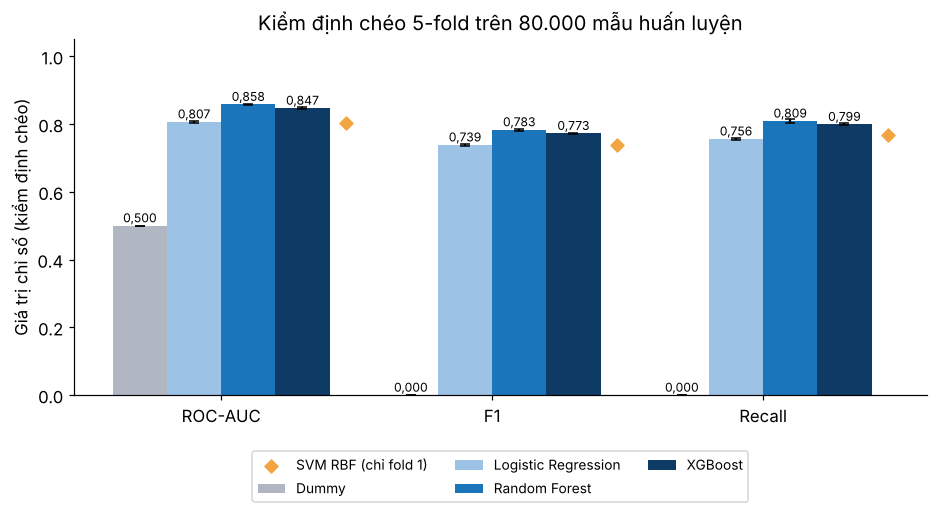

In [8]:
# Hình: so sánh kiểm định chéo (trung bình ± độ lệch chuẩn qua 5 fold)
models = ["Dummy", "Logistic Regression", "Random Forest", "XGBoost"]
show = [("roc_auc", "ROC-AUC"), ("f1", "F1"), ("recall", "Recall")]
fig, ax = plt.subplots(figsize=(10, 4.2)); w = 0.2; x = np.arange(len(show))
cols = [GR, LB, BLUE, NAVY]
for i, n in enumerate(models):
    mu = [SUM["cv"][n][m][0] for m, _ in show]; sd = [SUM["cv"][n][m][1] for m, _ in show]
    b = ax.bar(x + (i - 1.5) * w, mu, w, yerr=sd, capsize=3, color=cols[i], label=n)
    for xi, v in zip(x + (i - 1.5) * w, mu): ax.text(xi, v + 0.01, f"{v:.3f}".replace(".", ","), ha="center", fontsize=8)
ax.scatter([0 + 2.3 * w, 1 + 2.3 * w, 2 + 2.3 * w], [svm_res["roc_auc"], svm_res["f1"], svm_res["recall"]], marker="D", color=OR, zorder=3,
           label="SVM RBF (chỉ fold 1)")
ax.set_xticks(x); ax.set_xticklabels([s for _, s in show]); ax.set_ylim(0, 1.05); ax.set_ylabel("Giá trị chỉ số (kiểm định chéo)")
ax.legend(ncol=3, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, -0.32)); ax.set_title("Kiểm định chéo 5-fold trên 80.000 mẫu huấn luyện")
savefig("fig09_cv_so_sanh.png")

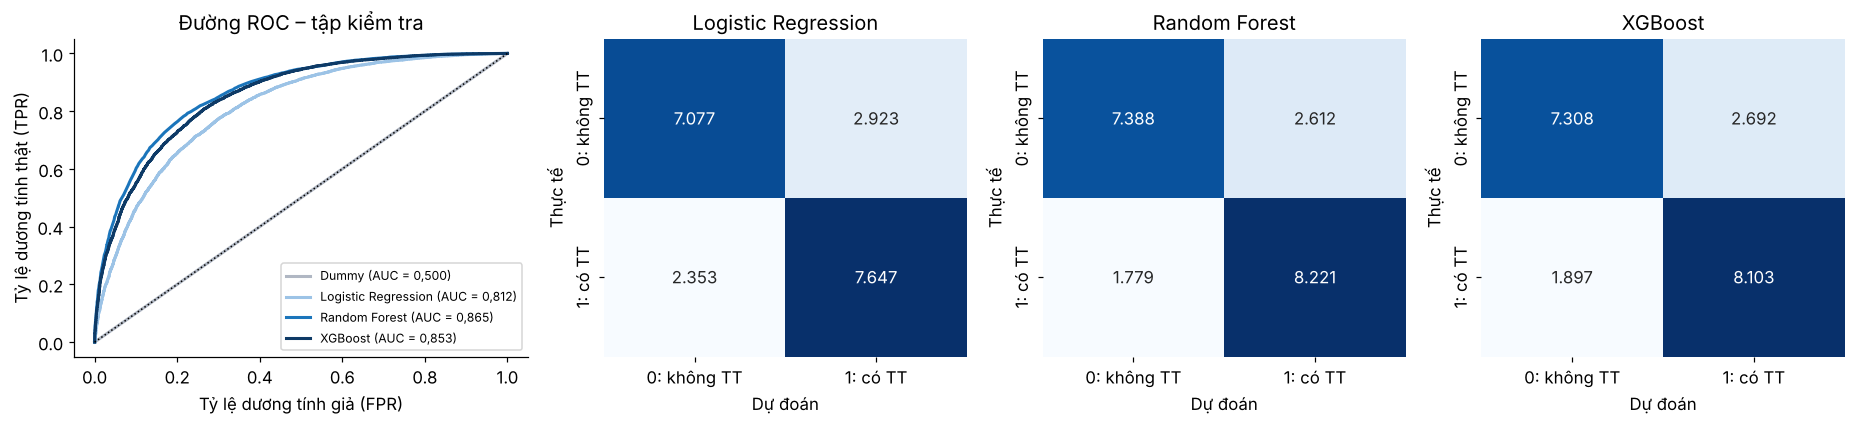

In [9]:
# Hình: đường ROC trên tập kiểm tra và ma trận nhầm lẫn của 3 mô hình
fig, axes = plt.subplots(1, 4, figsize=(17, 4), gridspec_kw={"width_ratios": [1.25, 1, 1, 1]})
for n, c in zip(models, cols):
    fpr, tpr, _ = roc_curve(y_test, proba[n]); axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUC = {SUM['test'][n]['roc_auc']:.3f})".replace(".", ","))
axes[0].plot([0, 1], [0, 1], ":", color="k", lw=1); axes[0].set_xlabel("Tỷ lệ dương tính giả (FPR)"); axes[0].set_ylabel("Tỷ lệ dương tính thật (TPR)")
axes[0].legend(fontsize=8, loc="lower right"); axes[0].set_title("Đường ROC – tập kiểm tra")
SUM["confusion"] = {}
for a, n in zip(axes[1:], models[1:]):
    cm = confusion_matrix(y_test, (proba[n] >= 0.5).astype(int)); SUM["confusion"][n] = cm.tolist()
    sns.heatmap(cm, annot=np.array([[f"{v:,}".replace(",", ".") for v in r] for r in cm]), fmt="", cmap="Blues", cbar=False, ax=a,
                xticklabels=["0: không TT", "1: có TT"], yticklabels=["0: không TT", "1: có TT"])
    a.set_xlabel("Dự đoán"); a.set_ylabel("Thực tế"); a.set_title(n)
plt.tight_layout(); savefig("fig10_roc_nham_lan.png")

## 6. Phân tích lỗi
Phân tích trên tập kiểm tra với mô hình có ROC-AUC cao nhất. Bậc của thuốc (số thuốc tương tác cùng) chỉ dùng để
**phân tích**, không đưa vào mô hình.

In [10]:
best = test_table.drop("Dummy")["roc_auc"].idxmax(); SUM["best_bkt2"] = best
pb = proba[best]; yhat = (pb >= 0.5).astype(int)
deg = drugs.set_index("drugbank_id")["degree"]
ana = test_df[["drug1", "drug2", "label"]].copy(); ana["p"] = pb; ana["pred"] = yhat
ana["sai"] = (ana.pred != ana.label).astype(int)
ana["deg_min"] = np.minimum(deg.loc[ana.drug1].values, deg.loc[ana.drug2].values)
fpm = {r.drugbank_id: r for r in drugs.itertuples()}
from rdkit.Chem import rdFingerprintGenerator, MolFromSmiles
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
bv = {d: gen.GetFingerprint(MolFromSmiles(s)) for d, s in zip(drugs.drugbank_id, drugs.smiles_std)}
ana["tanimoto"] = [DataStructs.TanimotoSimilarity(bv[a], bv[b]) for a, b in zip(ana.drug1, ana.drug2)]
ana["bin_deg"] = pd.cut(ana.deg_min, [-1, 50, 200, 500, 800, 2000], labels=["≤50", "51–200", "201–500", "501–800", ">800"])
ana["bin_tan"] = pd.cut(ana.tanimoto, [-0.01, 0.05, 0.1, 0.15, 0.25, 1.0], labels=["≤0,05", "0,05–0,10", "0,10–0,15", "0,15–0,25", ">0,25"])
def rates(g):
    pos, neg = g[g.label == 1], g[g.label == 0]
    return pd.Series({"Số cặp": len(g), "Tỷ lệ dương": g.label.mean(), "Tỷ lệ sai": g.sai.mean(),
                      "FN/dương": (pos.pred == 0).mean() if len(pos) else np.nan, "FP/âm": (neg.pred == 1).mean() if len(neg) else np.nan})
by_deg = ana.groupby("bin_deg", observed=True).apply(rates); by_tan = ana.groupby("bin_tan", observed=True).apply(rates)
display(by_deg.round(3)); display(by_tan.round(3))
SUM["err_by_deg"] = by_deg.round(4).reset_index().to_dict(orient="records"); SUM["err_by_tan"] = by_tan.round(4).reset_index().to_dict(orient="records")
cm = confusion_matrix(ana.label, ana.pred); SUM["best_fn"], SUM["best_fp"] = int(cm[1, 0]), int(cm[0, 1])

,Số cặp,Tỷ lệ dương,Tỷ lệ sai,FN/dương,FP/âm
bin_deg,,,,,
≤50,2674.0,0.022,0.077,0.831,0.060
51–200,2901.0,0.154,0.170,0.693,0.075
201–500,5018.0,0.430,0.328,0.341,0.319
501–800,6665.0,0.719,0.273,0.133,0.632
>800,2742.0,0.929,0.082,0.019,0.898


,Số cặp,Tỷ lệ dương,Tỷ lệ sai,FN/dương,FP/âm
bin_tan,,,,,
"≤0,05",2291.0,0.408,0.206,0.258,0.171
"0,05–0,10",7563.0,0.467,0.224,0.218,0.229
"0,10–0,15",7161.0,0.522,0.220,0.152,0.293
"0,15–0,25",2781.0,0.590,0.219,0.112,0.374
">0,25",204.0,0.721,0.196,0.088,0.474


In [11]:
# Thuốc xuất hiện trong nhiều cặp dự đoán sai nhất
names = drugs.set_index("drugbank_id")["name"]
long = pd.concat([ana[["drug1", "sai", "label"]].rename(columns={"drug1": "d"}), ana[["drug2", "sai", "label"]].rename(columns={"drug2": "d"})])
per = long.groupby("d").agg(so_cap=("sai", "size"), so_sai=("sai", "sum")); per["ty_le_sai"] = per.so_sai / per.so_cap
per = per[per.so_cap >= 30].sort_values("ty_le_sai", ascending=False)
per["Tên thuốc"] = names.loc[per.index].values; per["Bậc"] = deg.loc[per.index].values
display(per.head(10).round(3))
SUM["worst_drugs"] = per.head(8).round(4).reset_index().to_dict(orient="records")
SUM["corr_err_deg_drug"] = float(per[["ty_le_sai", "Bậc"]].corr(method="spearman").iloc[0, 1])

,so_cap,so_sai,ty_le_sai,Tên thuốc,Bậc
d,,,,,
DB00482,30,12,0.400,Celecoxib,1260
DB08901,30,11,0.367,Ponatinib,893
DB01093,31,11,0.355,Dimethyl sulfoxide,847
DB01086,31,10,0.323,Benzocaine,1062
DB00358,32,10,0.312,Mefloquine,781
DB00263,32,10,0.312,Sulfisoxazole,712
DB08981,42,13,0.310,Fenbufen,899
DB01394,36,11,0.306,Colchicine,892
DB09292,30,9,0.300,Sacubitril,741


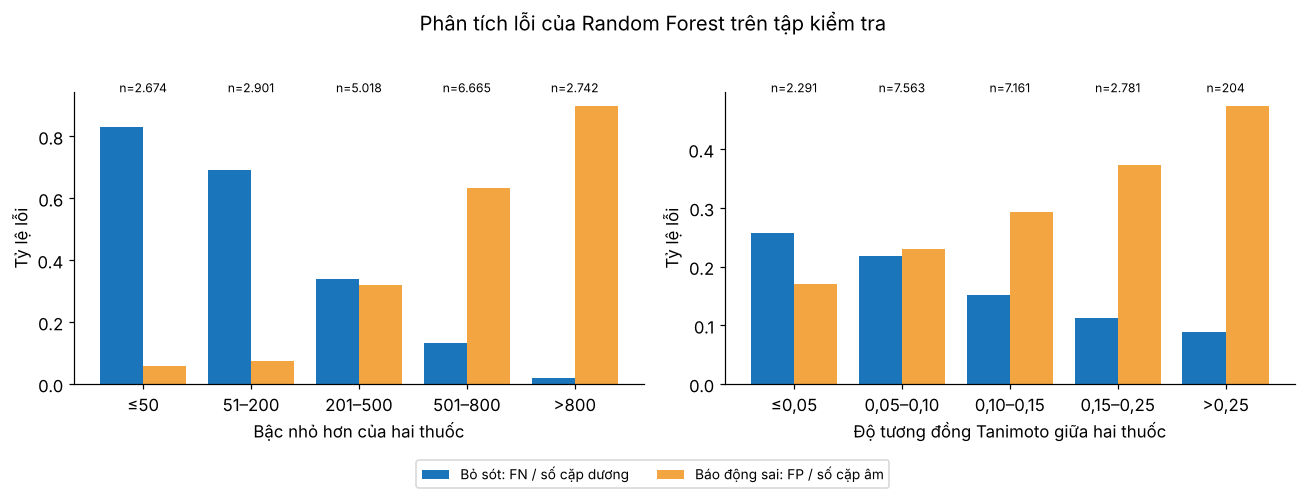

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, tb, xl in [(ax[0], by_deg, "Bậc nhỏ hơn của hai thuốc"), (ax[1], by_tan, "Độ tương đồng Tanimoto giữa hai thuốc")]:
    x = np.arange(len(tb)); a.bar(x - 0.2, tb["FN/dương"], 0.4, color=BLUE, label="Bỏ sót: FN / số cặp dương")
    a.bar(x + 0.2, tb["FP/âm"], 0.4, color=OR, label="Báo động sai: FP / số cặp âm")
    for xi, n in zip(x, tb["Số cặp"]): a.text(xi, max(tb["FN/dương"].max(), tb["FP/âm"].max()) * 1.05, f"n={int(n):,}".replace(",", "."), ha="center", fontsize=8)
    a.set_xticks(x); a.set_xticklabels(tb.index.astype(str)); a.set_xlabel(xl); a.set_ylabel("Tỷ lệ lỗi")
h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, ncol=2, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"Phân tích lỗi của {best} trên tập kiểm tra", y=1.02)
plt.tight_layout(); savefig("fig11_phan_tich_loi.png")

## 7. Đặc trưng ảnh hưởng nhiều đến dự đoán (XGBoost, độ quan trọng theo gain)

In [13]:
xgbp = final["XGBoost"]; keep = xgbp.named_steps["loc_hang_so"].get_support()
gain = xgbp.named_steps["clf"].get_booster().get_score(importance_type="gain")
imp = pd.Series(0.0, index=FEAT[keep])
for k, v in gain.items(): imp.iloc[int(k[1:])] = v
imp = imp / imp.sum()
grp = pd.Series({g: imp[[f.startswith(g) for f in imp.index]].sum() for g in ["A_morgan", "A_maccs", "B_morgan", "B_maccs"]})
print("Tỷ trọng độ quan trọng theo nhóm đặc trưng:\n", grp.round(3))
top = imp.sort_values(ascending=False).head(15)
mbits = sorted({int(f.split("_")[-1]) for f in top.index if "morgan" in f})
frag = morgan_bit_fragments(drugs, mbits)
def describe(f):
    side, kind, j = f.split("_"); j = int(j)
    return f"MACCS {j}: {maccs_description(j)}" if kind == "maccs" else f"Morgan bit {j}: {frag[j]}"
top_df = pd.DataFrame({"Đặc trưng": top.index, "Thuốc": [f[0] for f in top.index], "Mô tả": [describe(f) for f in top.index], "Tỷ trọng": top.values})
display(top_df.round(4))
SUM["imp_groups"] = grp.round(4).to_dict(); SUM["top_features"] = top_df.round(5).to_dict(orient="records")
SUM["imp_top15_share"] = float(top.sum())

Tỷ trọng độ quan trọng theo nhóm đặc trưng:
 A_morgan    0.382
A_maccs     0.060
B_morgan    0.484
B_maccs     0.073
dtype: float64


,Đặc trưng,Thuốc,Mô tả,Tỷ trọng
0,B_morgan_726,B,Morgan bit 726: ccc,0.0041
1,B_maccs_14,B,MACCS 14: [#16]-[#16],0.0027
2,B_maccs_40,B,MACCS 40: [#16]-[#8],0.0027
3,B_morgan_1002,B,Morgan bit 1002: [C@@][C@H](C)C,0.0027
4,B_morgan_537,B,Morgan bit 537: NCC(=O)[O-],0.0026
5,A_morgan_726,A,Morgan bit 726: ccc,0.0025
6,A_morgan_598,A,Morgan bit 598: CC(C)c,0.0022
7,A_morgan_166,A,Morgan bit 166: CCN,0.0019
8,B_morgan_783,B,Morgan bit 783: CN(C)c,0.0019
9,A_morgan_238,A,Morgan bit 238: ccc(c(c)O)c(c)o,0.0019


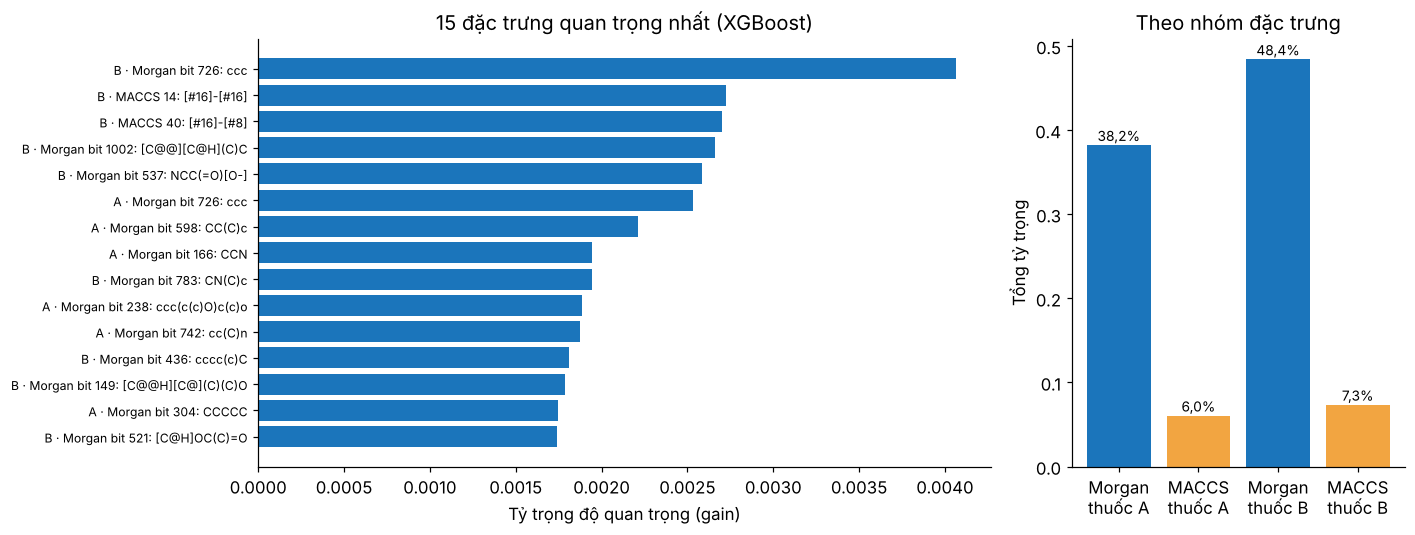

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2.2, 1]})
lab = [f"{r['Thuốc']} · {r['Mô tả']}"[:52] for _, r in top_df.iterrows()][::-1]
ax[0].barh(lab, top_df["Tỷ trọng"].values[::-1], color=BLUE); ax[0].set_xlabel("Tỷ trọng độ quan trọng (gain)"); ax[0].tick_params(axis="y", labelsize=8)
ax[0].set_title("15 đặc trưng quan trọng nhất (XGBoost)")
ax[1].bar(["Morgan\nthuốc A", "MACCS\nthuốc A", "Morgan\nthuốc B", "MACCS\nthuốc B"], grp.values, color=[BLUE, OR, BLUE, OR])
for i, v in enumerate(grp.values): ax[1].text(i, v + 0.005, f"{v:.1%}".replace(".", ","), ha="center", fontsize=9)
ax[1].set_ylabel("Tổng tỷ trọng"); ax[1].set_title("Theo nhóm đặc trưng")
plt.tight_layout(); savefig("fig12_dac_trung_quan_trong.png")

In [15]:
import sklearn, xgboost, platform
SUM["versions"] = {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgboost.__version__}
json.dump(SUM, open(f"{RES}/bkt2_summary.json", "w"), ensure_ascii=False, indent=1, default=float)
print("Đã lưu results/bkt2_summary.json, bkt2_cv_folds.csv, bkt2_test_predictions.csv.gz")

Đã lưu results/bkt2_summary.json, bkt2_cv_folds.csv, bkt2_test_predictions.csv.gz
